In [54]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap

In [86]:
from matplotlib import rc
rc('animation', html='jshtml')
colors = ["blue", "red", "white", "pink", "green", "black"]
cmap = ListedColormap(colors)

In [42]:
def hideValue(cells, value):
    cells[cells == value] = 0
    return cells

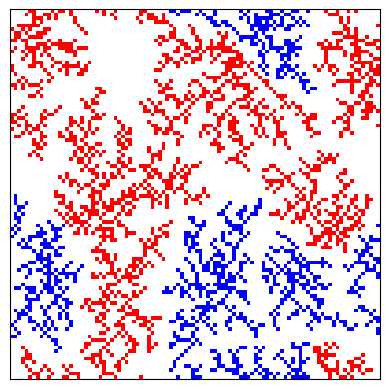

In [96]:
file = open("output/DLA.txt")
fileString = file.read().split("\n")
file.close()

meta_dla_data = [int(x) for x in fileString[0].split()]

shape = [meta_dla_data[0], meta_dla_data[1]]
min_val = meta_dla_data[2]
max_val = meta_dla_data[3]
iterations = len(fileString) - 1

fig, ax = plt.subplots()
ax.set_xticks([])
ax.set_yticks([])

ims = []
for i in range(iterations):
    cells = np.array([int(x) for x in fileString[i+1].split()])
    cells = np.reshape(cells, shape)
    cells = hideValue(cells, 3)
    
    im = ax.imshow(cells, animated=True, vmin=min_val, vmax=max_val, cmap=cmap, interpolation='nearest')

    ims.append([im])
    
ani = animation.ArtistAnimation(fig, ims, blit=True)
ani.save("output/DLA_animation.gif", writer=animation.PillowWriter(fps=10))

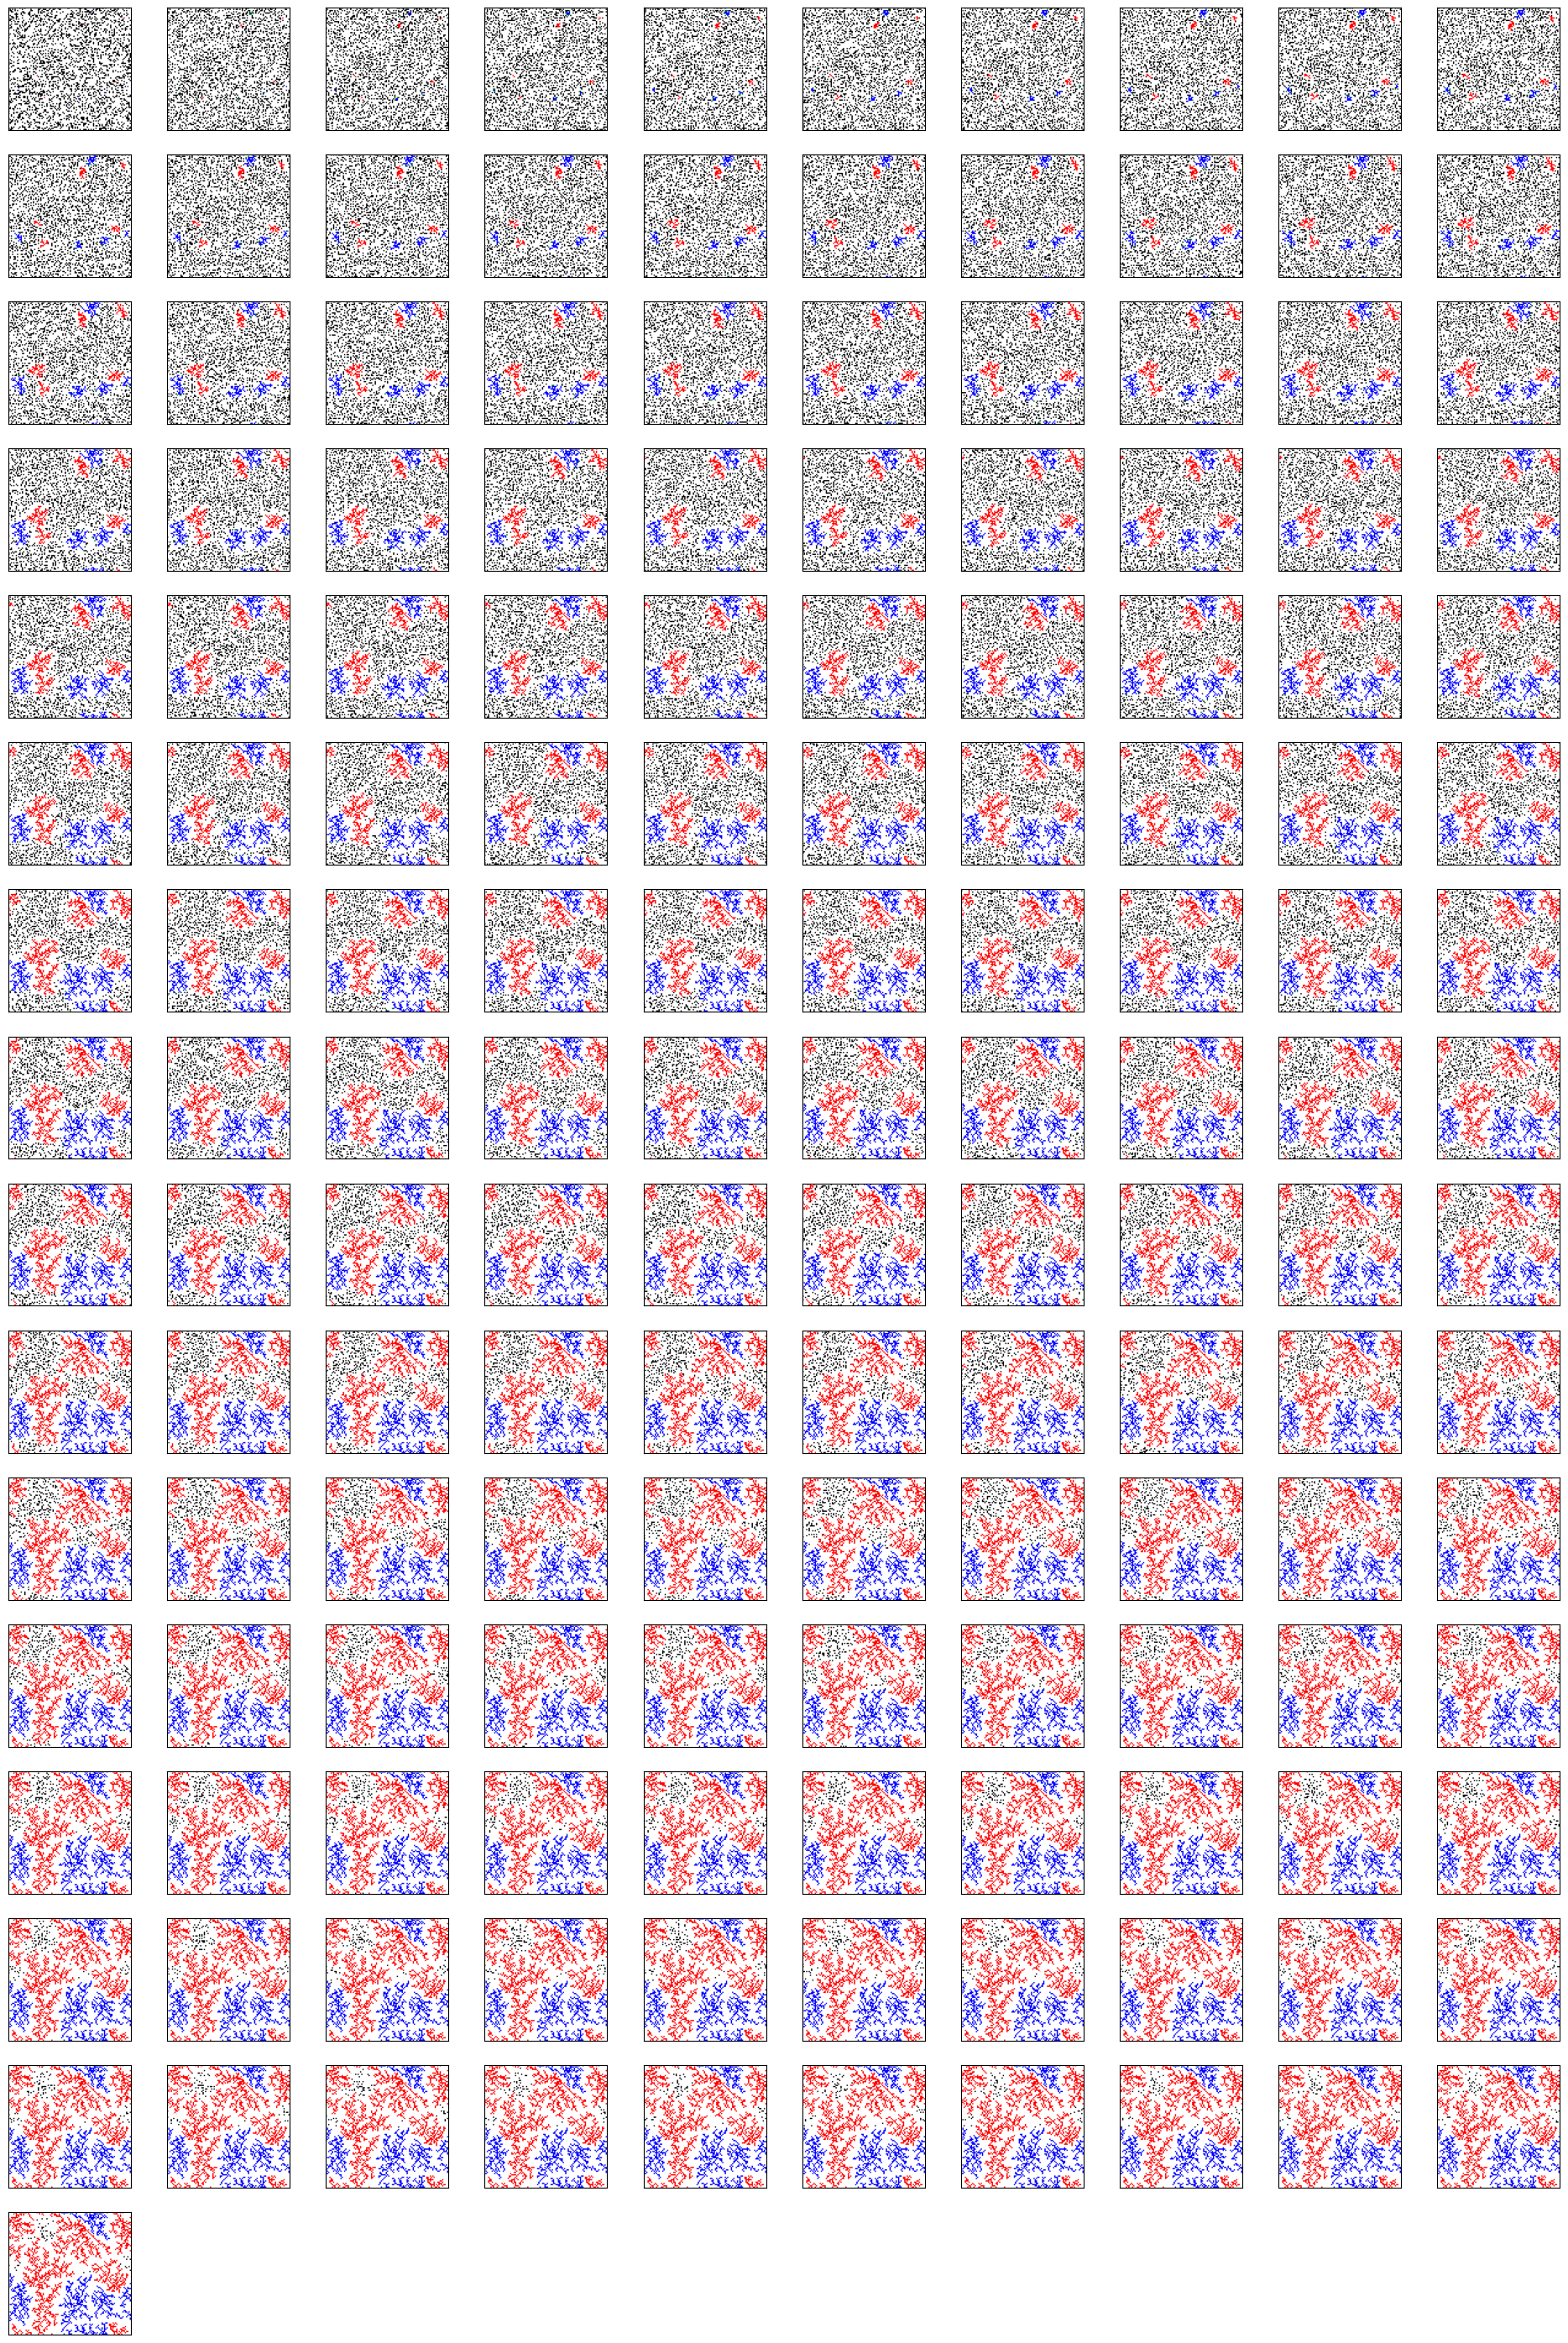

In [ ]:
figure_width = 10
figure_height = iterations//figure_width + 1
fig, ax = plt.subplots(figure_height, figure_width, figsize=[24,36])
for i in range(iterations):
  cells = np.array([int(x) for x in fileString[i+1].split()])
  cells = np.reshape(cells, shape)
  
  ax[i//figure_width, i % figure_width].imshow(cells, vmin=min_val, vmax=max_val, cmap=cmap)
  ax[i//figure_width, i % figure_width].set_xticks([])
  ax[i//figure_width, i % figure_width].set_yticks([])
for i in range(iterations, figure_width*figure_height):
  ax[i//figure_width, i % figure_width].remove()